# DeepHEx tutorial: standard 10x Genomics Visium

This notebook runs the complete DeepHEx workflow from a **standard Visium** Space Ranger output directory: preprocessing, histology feature extraction, interpolation, BCAF training, inference, and result export.

Run the cells in order. The workflow reuses the same model implementation as the Visium HD and Xenium examples; only the input adapter changes.

By default, the next cell downloads the public **Human Cervical Cancer (FFPE)** example from 10x Genomics and prepares its Space Ranger `outs` directory automatically. To use your own sample, set `USE_PUBLIC_EXAMPLE = False` and provide `USER_SPACERANGER_OUTS`.

## 1. Paths and configuration

Edit the values at the top of the next cell. With `USE_PUBLIC_EXAMPLE = True`, the notebook downloads the two public 10x files (about 30 MB). `WORK_DIR` will contain all DeepHEx-generated files.

UNI requires an accepted Hugging Face model licence. Create a token at <https://huggingface.co/settings/tokens>, accept the licence on <https://huggingface.co/MahmoodLab/UNI>, and expose the token as `HF_TOKEN`.

In [1]:
from pathlib import Path
import os
import sys

# Use the public tutorial sample, or switch off to run your own Space Ranger output.
USE_PUBLIC_EXAMPLE = True
USER_SPACERANGER_OUTS = Path('/path/to/spaceranger/outs')
WORK_DIR = Path.home() / 'DeepHEx_runs' / 'standard_visium_human_cervical_cancer_1'
PUBLIC_DATA_DIR = Path.home() / 'DeepHEx_data' / 'visium_human_cervical_cancer_1'
QUICK_TEST = False       # True: 2 epochs for an installation smoke test
NUM_TOP_GENES = 1000

# Locate the repository whether Jupyter starts in the repository root or notebooks/.
PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / 'pipeline.py').is_file():
    PROJECT_ROOT = PROJECT_ROOT.parent
sys.path.insert(0, str(PROJECT_ROOT))

if USE_PUBLIC_EXAMPLE:
    from scripts.download_example_visium import download_public_example

    SPACERANGER_OUTS = download_public_example(
        PUBLIC_DATA_DIR,
        dataset='human_cervical_cancer_1',
    )
else:
    SPACERANGER_OUTS = USER_SPACERANGER_OUTS.expanduser().resolve()

WORK_DIR.mkdir(parents=True, exist_ok=True)
display_path = lambda path: str(path).replace(str(Path.home()), '~')
print('Project:', display_path(PROJECT_ROOT))
print('Space Ranger outs:', display_path(SPACERANGER_OUTS))
print('Output directory:', display_path(WORK_DIR))
print('HF_TOKEN configured:', bool(os.environ.get('HF_TOKEN')))

Reusing matrix: ~/DeepHEx_data/visium_human_cervical_cancer_1/outs/filtered_feature_bc_matrix.h5
Reusing extracted spatial files: ~/DeepHEx_data/visium_human_cervical_cancer_1/outs/spatial
Dataset: human_cervical_cancer_1
Dataset page: https://www.10xgenomics.com/datasets/human-cervical-cancer-1-standard
Space Ranger outs: ~/DeepHEx_data/visium_human_cervical_cancer_1/outs
Project: ~/DeepHEx
Space Ranger outs: ~/DeepHEx_data/visium_human_cervical_cancer_1/outs
Output directory: ~/DeepHEx_runs/standard_visium_human_cervical_cancer_1
HF_TOKEN configured: False


## 2. Check the software environment

The first cell checks required Python modules, CUDA and the optional Hugging Face token. Training can run on CPU, but UNI inference and full training are substantially faster on a CUDA GPU.

In [2]:
from scripts.check_environment import main as check_environment

environment = check_environment()
assert environment['ready_for_preprocessing'], 'Install the missing packages before continuing.'

~/miniconda3/envs/cell2st/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


~/miniconda3/envs/cell2st/lib/python3.11/site-packages/lightning_fabric/__init__.py:29: UserWarning: pkg_resources is deprecated as an API. See https://setuptools.pypa.io/en/latest/pkg_resources.html. The pkg_resources package is slated for removal as early as 2025-11-30. Refrain from using this package or pin to Setuptools<81.
  __import__("pkg_resources").declare_namespace(__name__)


~/miniconda3/envs/cell2st/lib/python3.11/site-packages/transformers/utils/generic.py:441: UserWarning: torch.utils._pytree._register_pytree_node is deprecated. Please use torch.utils._pytree.register_pytree_node instead.
  _torch_pytree._register_pytree_node(


{
  "timestamp_utc": "2026-11-06T09:41:13.577038+00:00",
  "python": "3.11.6 | packaged by conda-forge | (main, Oct  3 2023, 10:40:35) [GCC 12.3.0]",
  "platform": "x86_64",
  "cpu_count": 112,
  "cuda_available": true,
  "cuda_device_count": 1,
  "cuda_devices": [
    "NVIDIA A100 80GB PCIe"
  ],
  "software_versions": {
    "numpy": "2.3.5",
    "pandas": "2.3.3",
    "scanpy": "1.11.5",
    "anndata": "0.12.7",
    "scipy": "1.17.1",
    "torch": "2.3.1+cu121",
    "pytorch_lightning": "1.9.5",
    "timm": "0.9.16",
    "huggingface_hub": "0.36.2",
    "Pillow": "13.0.0",
    "scikit-image": "0.26.0",
    "bin2cell": "0.3.4"
  },
  "missing_modules": [],
  "hf_token_configured": true,
  "ready_for_preprocessing": true,
  "ready_for_uni": true
}


## 3. Validate the Space Ranger input

Supported inputs are `filtered_feature_bc_matrix.h5` or the Matrix Market directory, `spatial/tissue_positions.csv` (or the legacy headerless `tissue_positions_list.csv`), `spatial/scalefactors_json.json`, and `spatial/tissue_hires_image.png`. A matching full-resolution image can be supplied explicitly.

In [3]:
from data.processing_Visium import discover_visium_inputs

visium_inputs = discover_visium_inputs(SPACERANGER_OUTS, image_level='auto')
for name, value in visium_inputs.__dict__.items():
    print(f'{name:20s} {value}')

outs_dir             ~/DeepHEx_data/visium_human_cervical_cancer_1/outs
matrix_path          ~/DeepHEx_data/visium_human_cervical_cancer_1/outs/filtered_feature_bc_matrix.h5
positions_path       ~/DeepHEx_data/visium_human_cervical_cancer_1/outs/spatial/tissue_positions_list.csv
scalefactors_path    ~/DeepHEx_data/visium_human_cervical_cancer_1/outs/spatial/scalefactors_json.json
image_path           ~/DeepHEx_data/visium_human_cervical_cancer_1/outs/spatial/tissue_hires_image.png
image_level          hires


## 4. Convert Space Ranger files to DeepHEx inputs

This step is deterministic. It selects in-tissue spots, intersects barcodes between the matrix and tissue positions, selects highly variable genes, rescales the histology image to 0.5 µm/pixel by default, and closes the individual spot footprints into a contiguous tissue mask. The latter is essential: inference then produces deep-learning values on the complete superpixel lattice rather than only on a spot-shaped dot lattice. The common files consumed by every downstream stage are written to `WORK_DIR`.

In [4]:
from data.processing_Visium import prepare_standard_visium

preprocessing_metadata = prepare_standard_visium(
    outs_dir=visium_inputs.outs_dir,
    output_dir=WORK_DIR,
    image_level=visium_inputs.image_level,
    output_um_per_pixel=0.5,
    spot_diameter_um=55.0,
    superpixel_size=16,
    num_top_genes=NUM_TOP_GENES,
    min_cells=10,
    hvg_flavor='seurat_v3',
)
preprocessing_metadata['preprocessing']

~/miniconda3/envs/cell2st/lib/python3.11/site-packages/anndata/_core/anndata.py:1808: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


~/miniconda3/envs/cell2st/lib/python3.11/site-packages/anndata/_core/anndata.py:1808: UserWarning: Variable names are not unique. To make them unique, call `.var_names_make_unique`.
  utils.warn_names_duplicates("var")


Prepared standard Visium data: 2781 spots x 1000 genes -> ~/DeepHEx_runs/standard_visium_human_cervical_cancer_1


{'n_spots': 2781,
 'n_genes_input': 17943,
 'n_genes_after_min_cells': 17179,
 'n_genes_selected': 1000,
 'min_cells': 10,
 'hvg_flavor': 'seurat_v3',
 'num_top_genes_requested': 1000,
 'source_um_per_pixel': 4.031561357448774,
 'output_um_per_pixel': 0.5,
 'image_rescale_factor': 8.063122714897547,
 'spot_diameter_um': 55.0,
 'spot_radius_output_pixels': 55.0,
 'superpixel_size_output_pixels': 16,
 'mask_grid_shape': [938, 1008],
 'mask_dilation_iterations': 1,
 'expression_matrix_shape': [2781, 1000]}

## 5. Quality control: image, spots and mask

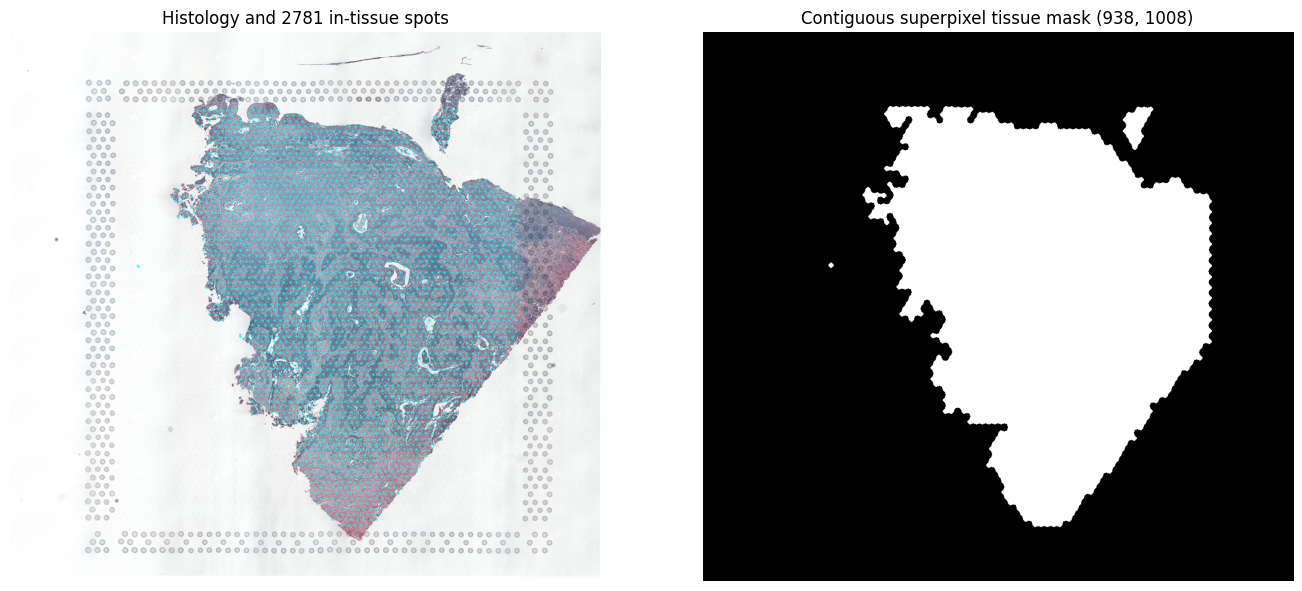

In [3]:
import numpy as np
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt

# The full-resolution H&E often exceeds Pillow's default safety threshold.
# Load a display-sized copy for QC instead of materialising the full image.
Image.MAX_IMAGE_PIXELS = None
histology = Image.open(WORK_DIR / 'he.jpg').convert('RGB')
histology.thumbnail((2400, 2400), Image.Resampling.LANCZOS)
image = np.asarray(histology)
locs = pd.read_csv(WORK_DIR / 'locs.csv', index_col=0)
counts = pd.read_csv(WORK_DIR / 'cnts.csv', index_col=0)
mask = np.asarray(Image.open(WORK_DIR / 'mask.png')) > 0

assert locs.index.equals(counts.index)
assert counts.shape[1] == len((WORK_DIR / 'gene-names.txt').read_text().splitlines())

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
axes[0].imshow(image)
image_scale_x = image.shape[1] / Image.open(WORK_DIR / 'he.jpg').width
image_scale_y = image.shape[0] / Image.open(WORK_DIR / 'he.jpg').height
axes[0].scatter(
    locs['x'] * image_scale_x,
    locs['y'] * image_scale_y,
    s=1,
    c='cyan',
    alpha=0.6,
)
axes[0].set_title(f'Histology and {len(locs)} in-tissue spots')
axes[1].imshow(mask, cmap='gray')
axes[1].set_title(f'Contiguous superpixel tissue mask {mask.shape}')
for ax in axes:
    ax.axis('off')
plt.tight_layout()
plt.savefig(WORK_DIR / 'qc_visium_spots_and_mask.png', dpi=200, bbox_inches='tight')
plt.show()

## 6. Create a reproducible run configuration

The configuration is saved beside the outputs. It controls the random seed, learning rate, batch size, BCAF latent width, number of states and output format.

In [2]:
import torch
import yaml

CONFIG = {
    'global': {
        'input_type': 'visium',
        'directory': str(WORK_DIR) + '/',
        'pseudo_radius': 55,
        'superpixel_size': 16,
        'seed': 42,
    },
    'histology': {'token_env': 'HF_TOKEN', 'model_name': 'UNI'},
    'train': {
        'epochs': 2 if QUICK_TEST else 400,
        'device': 'cuda' if torch.cuda.is_available() else 'cpu',
        'gpu_ids': [0] if torch.cuda.is_available() else 1,
        'n_states': 1,
        'BCAF_embeddings': 256,
        'k_neighbors': 6,
        'learning_rate': 1e-4,
        'batch_size': 'auto',
        'load_saved': False,
        'enhance': True,
    },
    'preprocessing': {'visium': {'outs_dir': str(SPACERANGER_OUTS)}},
    'export': {
        'enabled': True,
        'h5ad_name': 'deephex_expression.h5ad',
        'csv': False,
        'csv_name': 'deephex_expression.csv',
        'metadata_name': 'run_metadata.json',
    },
}

config_path = WORK_DIR / 'deephex_visium_config.yaml'
config_path.write_text(yaml.safe_dump(CONFIG, sort_keys=False), encoding='utf-8')
print(config_path.read_text().replace(str(Path.home()), '~'))

global:
  input_type: visium
  directory: ~/DeepHEx_runs/standard_visium_human_cervical_cancer_1/
  pseudo_radius: 55
  superpixel_size: 16
  seed: 42
histology:
  token_env: HF_TOKEN
  model_name: UNI
train:
  epochs: 400
  device: cuda
  gpu_ids:
  - 0
  n_states: 1
  BCAF_embeddings: 256
  k_neighbors: 6
  learning_rate: 0.0001
  batch_size: auto
  load_saved: false
  enhance: true
preprocessing:
  visium:
    outs_dir: ~/DeepHEx_data/visium_human_cervical_cancer_1/outs
export:
  enabled: true
  h5ad_name: deephex_expression.h5ad
  csv: false
  csv_name: deephex_expression.csv
  metadata_name: run_metadata.json



## 7. Extract UNI histology features

UNI is downloaded through `timm`/Hugging Face on first use. The output `Histology_feature_map.pickle` contains one feature map on the 16-pixel superpixel grid.

In [7]:
from model.histology_ext import run_feature_extraction

uni_metadata = run_feature_extraction(CONFIG)
uni_metadata

Global seed set to 42


The size of the histological image is:(15008, 16128, 3)


{'histology_image_shape': [15008, 16128, 3],
 'feature_map_shape': [938, 1008, 1024],
 'uni_feature_seconds': 79.47615513100754}

## 8. Build the initial high-resolution expression estimates

In [8]:
from model.GetHr import run_get_hr

run_get_hr(CONFIG)
print('Interpolated expression:', (WORK_DIR / 'HRcnts111.csv').stat().st_size, 'bytes')
print('Interpolated locations:', (WORK_DIR / 'HRlocs111.csv').stat().st_size, 'bytes')

Meta Info: {'x_step': np.float64(69.19999999999982), 'y_step': np.float64(134.70000000000073), 'x_offset': np.float64(28.687912000008964), 'y_offset': np.float64(104.11914099998921)}


Total Spots: 8676
Interpolated expression: 81942803 bytes
Interpolated locations: 390681 bytes


## 9. Train BCAF and reconstruct expression

In [9]:
from pipeline import run_main

training_metadata = run_main(CONFIG, write_exports=False)
training_metadata

Global seed set to 42


x: (938, 1008, 1024) , y: (2781, 1000)


Global seed set to 42


GPU available: True (cuda), used: True


TPU available: False, using: 0 TPU cores


IPU available: False, using: 0 IPUs


... (9 outputs left out)

~/DeepHEx_runs/standard_visium_human_cervical_cancer_1/states/00/history.png


~/DeepHEx/pipeline.py:158: UserWarning: Creating a tensor from a list of numpy.ndarrays is extremely slow. Please consider converting the list to a single numpy.ndarray with numpy.array() before converting to a tensor. (Triggered internally at ../torch/csrc/utils/tensor_new.cpp:274.)
  x = torch.tensor(x, device=model.device)


All genes have been saved in ~/DeepHEx_runs/standard_visium_human_cervical_cancer_1/cnts-super/..


{'batch_size': 32,
 'n_training_spots': 2781,
 'train_inference_seconds': 1402.5697108160239}

## 10. Export the final result

In [4]:
import warnings

with warnings.catch_warnings():
    warnings.simplefilter('ignore')
    from utils.export import export_deephex_results
    output_metadata = export_deephex_results(
        WORK_DIR,
        CONFIG,
        stage_metadata=training_metadata,
    )
output_metadata['dimensions']

Exported DeepHEx results: 268808 superpixels x 1000 genes to ~/DeepHEx_runs/standard_visium_human_cervical_cancer_1/deephex_expression.h5ad


{'n_superpixels': 268808,
 'n_genes': 1000,
 'expression_matrix': [268808, 1000],
 'histology_mask_grid': [938, 1008],
 'superpixel_size_pixels': 16,
 'output_um_per_pixel': 0.5}

## 11. Load and inspect the result

The reconstructed expression is a dense estimate on the tissue-masked superpixel grid. Values are model outputs on the learned expression scale, not extra counts measured by Space Ranger.

AnnData: 268,808 superpixels x 1,000 genes
obs columns: ['superpixel_row', 'superpixel_col', 'x', 'y', 'x_um', 'y_um']
uns: ['deephex']
                    superpixel_row  superpixel_col       x       y    x_um  \
spatial_id                                                                   
superpixel_128_318             128             318  5096.0  2056.0  2548.0   
superpixel_128_319             128             319  5112.0  2056.0  2556.0   
superpixel_128_320             128             320  5128.0  2056.0  2564.0   
superpixel_128_328             128             328  5256.0  2056.0  2628.0   
superpixel_128_329             128             329  5272.0  2056.0  2636.0   

                      y_um  
spatial_id                  
superpixel_128_318  1028.0  
superpixel_128_319  1028.0  
superpixel_128_320  1028.0  
superpixel_128_328  1028.0  
superpixel_128_329  1028.0  


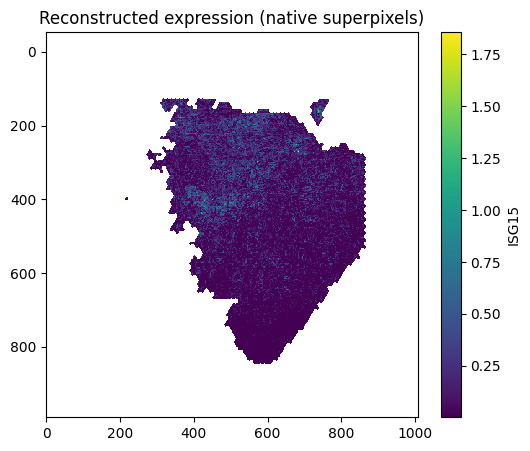

In [2]:
import anndata as ad
from IPython.display import display
from PIL import Image

result = ad.read_h5ad(WORK_DIR / 'deephex_expression.h5ad', backed='r')
print(f'AnnData: {result.n_obs:,} superpixels x {result.n_vars:,} genes')
print('obs columns:', list(result.obs.columns))
print('uns:', list(result.uns.keys()))
print(result.obs.head())

gene = result.var_names[0]
mask = np.asarray(Image.open(WORK_DIR / 'mask.png')) > 0
grid = np.full(mask.shape, np.nan)
rows = result.obs['superpixel_row'].to_numpy(dtype=int)
cols = result.obs['superpixel_col'].to_numpy(dtype=int)
grid[rows, cols] = result[:, gene].X.ravel()

# Render the native superpixel grid directly: one pixel per learned region,
# without aggregating predictions back to the original Visium spots.
plt.figure(figsize=(6, 5))
plt.imshow(
    np.ma.masked_invalid(grid),
    cmap='viridis',
    interpolation='nearest',
    extent=(0, grid.shape[1], grid.shape[0], 0),
)
plt.colorbar(label=gene)
plt.title('Reconstructed expression (native superpixels)')
plt.axis('equal')
display(plt.gcf())
plt.close()

## 12. Publication-style visualization

Following the layout in Fig. 6c, the top row shows the measured Visium spots (`Raw`) and the bottom row shows the native DeepHEx super-resolution maps; the latter are not re-aggregated to spot resolution. The two rows use separate qualitative colour ramps tuned for sparse spot data and continuous tissue maps. If the manuscript genes are absent from the current 1,000-gene panel, biologically relevant retained genes are shown instead. SVG and PDF text remain editable; TIFF is exported at 600 dpi.

Genes not retained as HVGs: TP53, RB1, CDK4
Visualized genes: TOP2A, EPCAM, KRT5


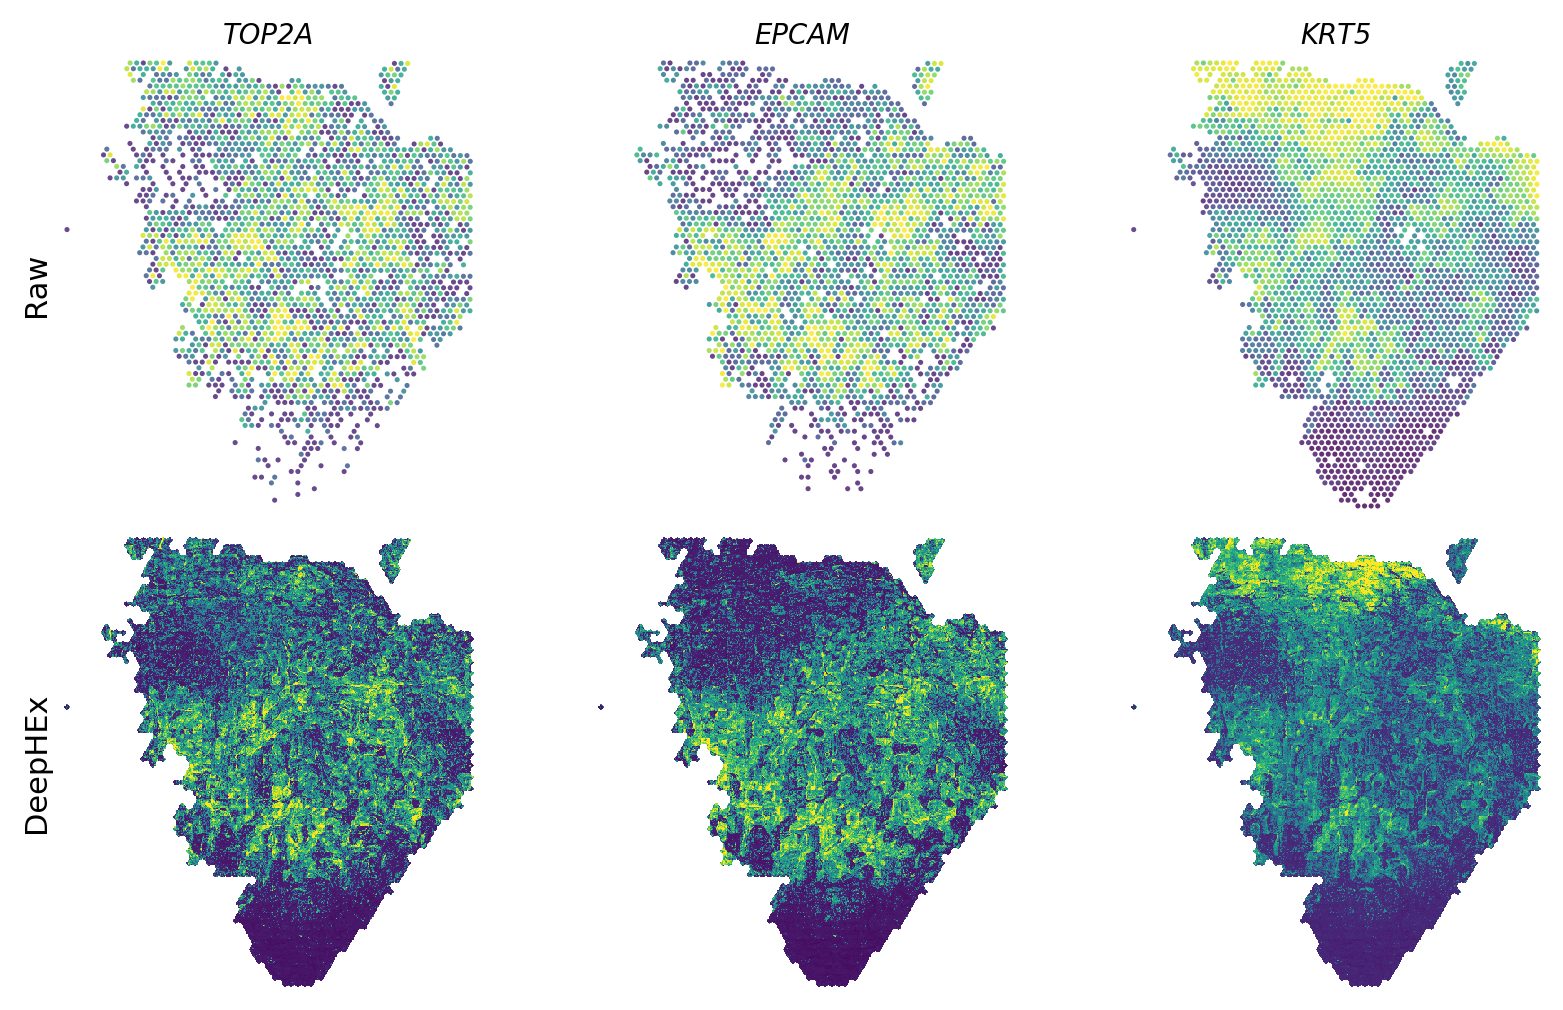

Editable vector: ~/DeepHEx_runs/standard_visium_human_cervical_cancer_1/figures/standard_visium_expression_maps.svg
High-resolution TIFF: ~/DeepHEx_runs/standard_visium_human_cervical_cancer_1/figures/standard_visium_expression_maps.tiff


In [2]:
from IPython.display import Image, display
from utils.visualization import plot_standard_visium_expression

# The manuscript reports TP53, RB1 and CDK4. When a gene is not retained in
# this run's 1,000 highly variable genes, the helper fills the panel with the
# biologically relevant fallback genes below and reports the substitutions.
expression_fig, plotted_genes, expression_paths = plot_standard_visium_expression(
    WORK_DIR,
    requested_genes=('TP53', 'RB1', 'CDK4'),
    fallback_genes=('TOP2A', 'EPCAM', 'KRT5', 'ISG15'),
)
display(Image(filename=expression_paths['png']))
print('Editable vector:', expression_paths['svg'].replace(str(Path.home()), '~'))
print('High-resolution TIFF:', expression_paths['tiff'].replace(str(Path.home()), '~'))
plt.close(expression_fig)

In [8]:
from utils.visualization import compute_spatial_autocorrelation

metrics_path = WORK_DIR / 'deephex_spatial_metrics.csv'
expression_path = WORK_DIR / 'deephex_expression.h5ad'
metrics_are_current = (
    metrics_path.is_file()
    and metrics_path.stat().st_mtime >= expression_path.stat().st_mtime
)
if metrics_are_current:
    spatial_metrics = pd.read_csv(metrics_path)
    print(f'Loaded current metrics: {metrics_path.name}')
else:
    spatial_metrics = compute_spatial_autocorrelation(
        WORK_DIR / 'deephex_expression.h5ad',
        WORK_DIR / 'mask.png',
    )
    spatial_metrics.to_csv(metrics_path, index=False)
    print(f'Computed metrics: {metrics_path.name}')

assert len(spatial_metrics) == result.n_vars
spatial_metrics[['moran_i', 'geary_c']].describe().T

Computed metrics: deephex_spatial_metrics.csv


,count,mean,std,min,25%,50%,75%,max
moran_i,1000.0,0.622927,0.085792,0.234983,0.560045,0.618897,0.685314,0.870720
geary_c,1000.0,0.376162,0.087170,0.129622,0.311058,0.381855,0.439690,0.766812


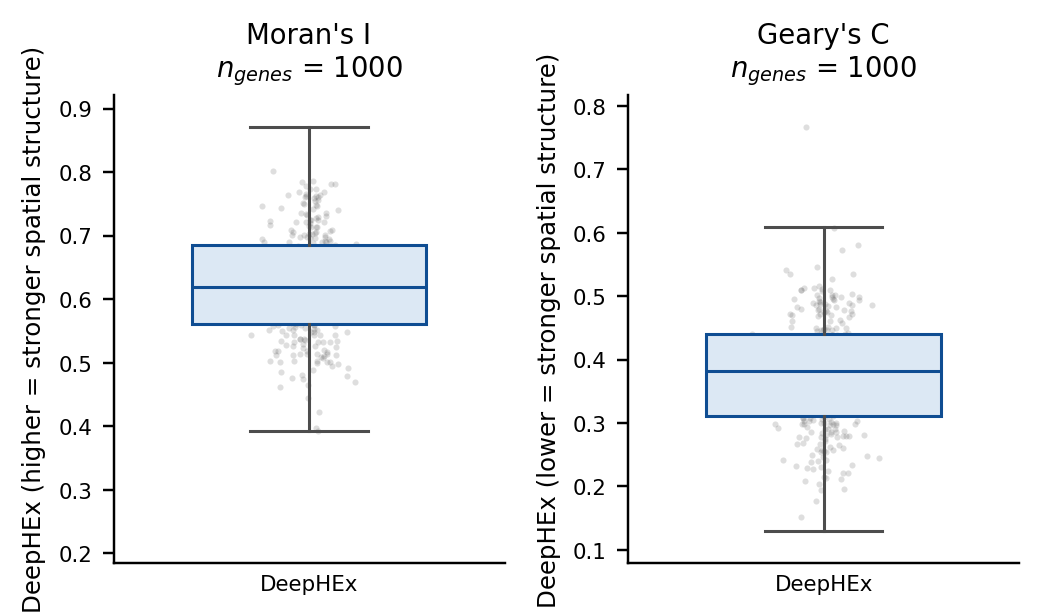

Editable vector: ~/DeepHEx_runs/standard_visium_human_cervical_cancer_1/figures/standard_visium_metric_boxplots.svg
High-resolution TIFF: ~/DeepHEx_runs/standard_visium_human_cervical_cancer_1/figures/standard_visium_metric_boxplots.tiff


In [9]:
from utils.visualization import plot_metric_boxplots

metric_fig, metric_paths = plot_metric_boxplots(
    spatial_metrics,
    columns=('moran_i', 'geary_c'),
    titles=("Moran's I", "Geary's C"),
    direction=(
        "DeepHEx (higher = stronger spatial structure)",
        "DeepHEx (lower = stronger spatial structure)",
    ),
    output_stem=WORK_DIR / 'figures' / 'standard_visium_metric_boxplots',
)
display(Image(filename=metric_paths['png']))
print('Editable vector:', metric_paths['svg'].replace(str(Path.home()), '~'))
print('High-resolution TIFF:', metric_paths['tiff'].replace(str(Path.home()), '~'))
plt.close(metric_fig)

## 13. Output checklist

After a successful run, the working directory contains:

- `he.jpg`: histology rescaled to the model grid and padded to a multiple of 224 pixels.
- `locs.csv`: Space Ranger spot centres in scaled image pixels; `x` is horizontal and `y` is vertical.
- `cnts.csv`: selected expression values with spot barcodes as rows.
- `gene-names.txt`: selected genes in matrix-column order.
- `mask.png`: contiguous tissue mask on the 16-pixel superpixel grid; spot footprints are closed using the measured spot-lattice spacing.
- `HRcnts.csv` and `HRlocs.csv`: interpolated training lattice.
- `states/`: checkpoints, training histories and embeddings.
- `cnts-super/`: one reconstructed 2-D array per gene.
- `deephex_expression.h5ad`: unified final expression matrix and spatial metadata.
- `deephex_coordinates.csv`: final superpixel coordinates.
- `run_metadata.json`: parameters, versions, dimensions and resource measurements.

- `figures/standard_visium_expression_maps.{svg,pdf,tiff,png}`: matched spot and super-resolution expression maps.
- `deephex_spatial_metrics.csv`: gene-wise Moran's I, Geary's C and non-zero fraction.
- `figures/standard_visium_metric_boxplots.{svg,pdf,tiff,png}`: DeepHEx-only metric distributions.


## Command-line equivalent

Once the paths are filled in, the same workflow can be run without Jupyter:

```bash
python interface.py --config deephex_visium_config.yaml --input-type visium
```

To prepare inputs only:

```bash
python scripts/prepare_visium.py \
  --outs /path/to/spaceranger/outs \
  --output-dir /path/to/deephex-standard-visium-work
```
